# CNN from Scratch using NumPy (CIFAR-10)

Completing the CNN step by step using the same pattern: section headings, tensor shape comments, and explicit forward/backward implementations.

Model: Conv2D -> ReLU -> MaxPool -> Conv2D -> ReLU -> MaxPool -> Flatten -> Dense -> Softmax + Cross Entropy.

In [1]:
import os
import tarfile
import urllib.request
import pickle
import time
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

np.random.seed(42)

# Data Loading

CIFAR-10 has 50,000 training images and 10,000 test images.
If the dataset is not present at the path below, this cell downloads it.

In [2]:
root = os.path.expanduser("~/Downloads/cifar-10-batches-py")
url = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"

if not os.path.isdir(root):
    parent = os.path.dirname(root)
    os.makedirs(parent, exist_ok=True)
    archive_path = os.path.join(parent, "cifar-10-python.tar.gz")
    if not os.path.isfile(archive_path):
        print("Downloading CIFAR-10...")
        urllib.request.urlretrieve(url, archive_path)
    print("Extracting CIFAR-10...")
    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(path=parent)

print("Dataset path:", root)
print(os.listdir(root)[:6])

Dataset path: /home/anant/Downloads/cifar-10-batches-py
['data_batch_5', 'data_batch_1', 'data_batch_2', 'test_batch', 'readme.html', 'data_batch_3']


In [3]:
def load_batch(file_path):
    with open(file_path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")
    return batch

files = [f"data_batch_{i}" for i in range(1,6)]
files.append("test_batch")

batches = []
for file in files:
    file_path = os.path.join(root,file)
    batches.append(load_batch(file_path))

x_train = np.concatenate([batch[b"data"] for batch in batches[:5]],axis=0)
y_train = np.concatenate([batch[b"labels"] for batch in batches[:5]],axis=0)
x_test = np.array(batches[5][b"data"])
y_test = np.array(batches[5][b"labels"])

print(x_train.shape,y_train.shape)
print(x_test.shape,y_test.shape)

(50000, 3072) (50000,)
(10000, 3072) (10000,)


In [4]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(x_train))

x_train = x_train[indices]
y_train = y_train[indices]

x_val = x_train[:5000]
y_val = y_train[:5000]
x_train = x_train[5000:]
y_train = y_train[5000:]

x_train = x_train.reshape(-1,3,32,32)
x_val = x_val.reshape(-1,3,32,32)
x_test = x_test.reshape(-1,3,32,32)

print(x_train.shape,y_train.shape)
print(x_val.shape,y_val.shape)
print(x_test.shape,y_test.shape)

(45000, 3, 32, 32) (45000,)
(5000, 3, 32, 32) (5000,)
(10000, 3, 32, 32) (10000,)


# Visualization

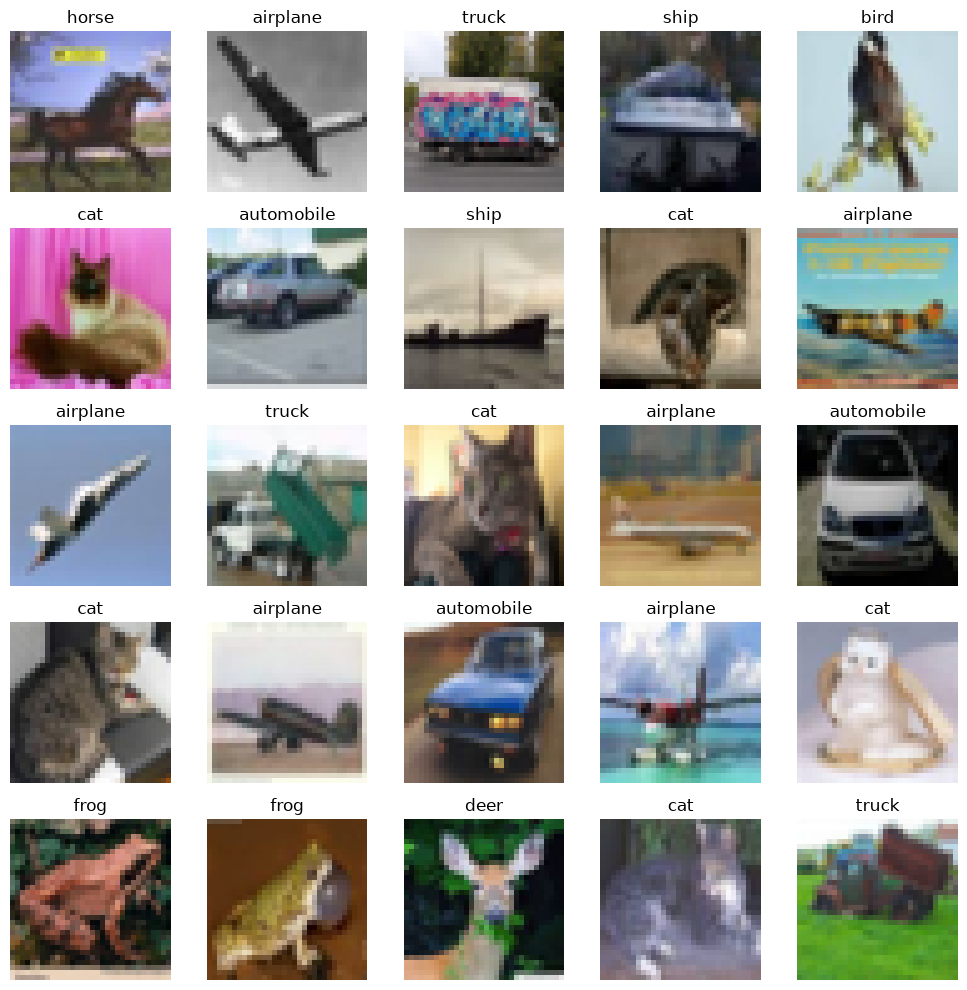

In [5]:
classes = ["airplane","automobile","bird","cat","deer",
           "dog","frog","horse","ship","truck"]

fig,axes = plt.subplots(5,5,figsize=(10,10))
for i,ax in enumerate(axes.flat):
    img = x_train[i].transpose(1,2,0)
    ax.imshow(img)
    ax.set_title(classes[y_train[i]])
    ax.axis("off")
plt.tight_layout()
plt.show()

# Normalization

In [6]:
print(x_train.max(),x_train.min())
print(x_val.max(),x_val.min())
print(x_test.max(),x_test.min())

x_train = x_train.astype(np.float32)/255
x_val = x_val.astype(np.float32)/255
x_test = x_test.astype(np.float32)/255

print(x_train.max(),x_train.min())
print(x_val.max(),x_val.min())
print(x_test.max(),x_test.min())

255 0
255 0
255 0
1.0 0.0
1.0 0.0
1.0 0.0


# Model Architecture

Small enough for NumPy training, while completing the full pipeline.

Input: (N,3,32,32)
Conv2D(3 -> 8) -> ReLU -> MaxPool(2)
Conv2D(8 -> 16) -> ReLU -> MaxPool(2)
Flatten -> Dense(10)

In [7]:
class Conv2D:
    def __init__(self,inpt_chnl,num_ker,k_row,k_col,stride,pad,img_r,img_c):
        fan_in = inpt_chnl*k_row*k_col
        std = np.sqrt(2/fan_in)

        self.stride = stride
        self.num_ker = num_ker
        self.inpt_chnl = inpt_chnl
        self.k_row = k_row
        self.k_col = k_col
        self.w = (np.random.randn(num_ker,inpt_chnl,k_row,k_col)*std).astype(np.float32)
        self.b = np.zeros(num_ker,dtype=np.float32)

        self.H_out = (img_r-k_row+2*pad)//stride + 1
        self.W_out = (img_c-k_col+2*pad)//stride + 1
        self.pad = pad

        self.x = None
        self.trans_x = None
        self.w_flat = None
        self.dl_dw = None
        self.dl_db = None

    def im2col(self,batch_size):
        windows = sliding_window_view(self.x,(self.k_row,self.k_col),axis=(2,3))
        windows = windows[:,:,::self.stride,::self.stride,:,:]
        self.trans_x = windows.transpose(0,2,3,1,4,5).reshape(
            batch_size*self.H_out*self.W_out,
            self.inpt_chnl*self.k_row*self.k_col
        )
        self.w_flat = self.w.reshape(self.num_ker,-1)
        return self.trans_x,self.w_flat

    def forward(self,x):
        batch_size = x.shape[0]
        if self.pad>0:
            p = self.pad
            self.x = np.pad(x,((0,0),(0,0),(p,p),(p,p)),mode="constant")
        else:
            self.x = x

        self.im2col(batch_size)
        z = self.trans_x @ self.w_flat.T + self.b
        z = z.reshape(batch_size,self.H_out,self.W_out,self.num_ker)
        z = z.transpose(0,3,1,2)
        return z

    def backward(self,ingrad):
        batch_size = self.x.shape[0]

        # (N,F,Ho,Wo) -> (N*Ho*Wo,F)
        dl_dz = ingrad.transpose(0,2,3,1).reshape(
            batch_size*self.H_out*self.W_out,self.num_ker
        )

        # gradients for weights and bias
        dl_dwcol = dl_dz.T @ self.trans_x
        self.dl_dw = dl_dwcol.reshape(self.w.shape)
        self.dl_db = ingrad.sum(axis=(0,2,3))

        # gradient for input patches
        dl_dxcol = dl_dz @ self.w_flat
        dl_dxcol = dl_dxcol.reshape(
            batch_size,self.H_out,self.W_out,
            self.inpt_chnl,self.k_row,self.k_col
        )

        # col2im: accumulate patch gradients back into input locations
        dl_dx = np.zeros_like(self.x)
        for r in range(self.k_row):
            for c in range(self.k_col):
                patch_grad = dl_dxcol[:,:,:,:,r,c].transpose(0,3,1,2)
                h_start = r
                h_end = r+self.stride*self.H_out
                w_start = c
                w_end = c+self.stride*self.W_out
                dl_dx[:,:,h_start:h_end:self.stride,w_start:w_end:self.stride] += patch_grad

        if self.pad>0:
            p = self.pad
            dl_dx = dl_dx[:,:,p:-p,p:-p]

        return dl_dx

    def update(self,lr):
        self.w -= lr*self.dl_dw
        self.b -= lr*self.dl_db

In [8]:
class RELU:
    def __init__(self):
        self.pos = None

    def forward(self,z):
        self.pos = z>0
        a = np.maximum(0,z)
        return a

    def backward(self,dl_da):
        da_dz = self.pos
        dl_dz = dl_da*da_dz
        return dl_dz

In [9]:
class MaxPool:
    def __init__(self,stride,pool_r,pool_c):
        self.stride = stride
        self.pool_r = pool_r
        self.pool_c = pool_c
        self.windows = None
        self.idx = None
        self.input_shape = None

    def forward(self,a):
        self.input_shape = a.shape
        self.windows = sliding_window_view(a,(self.pool_r,self.pool_c),axis=(2,3))
        self.windows = self.windows[:,:,::self.stride,::self.stride,:,:]

        flat_windows = self.windows.reshape(*self.windows.shape[:4],self.pool_r*self.pool_c)
        self.idx = np.argmax(flat_windows,axis=-1)
        pooled = np.max(flat_windows,axis=-1)
        return pooled

    def backward(self,dl_da):
        N,C,Ho,Wo = dl_da.shape
        dl_windows = np.zeros((N,C,Ho,Wo,self.pool_r*self.pool_c),dtype=dl_da.dtype)

        # send gradient to the maximum location from forward
        np.put_along_axis(dl_windows,self.idx[...,None],dl_da[...,None],axis=-1)
        dl_windows = dl_windows.reshape(N,C,Ho,Wo,self.pool_r,self.pool_c)

        dl_dx = np.zeros(self.input_shape,dtype=dl_da.dtype)
        for r in range(self.pool_r):
            for c in range(self.pool_c):
                patch_grad = dl_windows[:,:,:,:,r,c]
                h_start = r
                h_end = r+self.stride*Ho
                w_start = c
                w_end = c+self.stride*Wo
                dl_dx[:,:,h_start:h_end:self.stride,w_start:w_end:self.stride] += patch_grad

        return dl_dx

In [10]:
class Flatten:
    def __init__(self):
        self.input_shape = None

    def forward(self,a):
        self.input_shape = a.shape
        return a.reshape(a.shape[0],-1)

    def backward(self,dl_da):
        return dl_da.reshape(self.input_shape)

In [11]:
class DenseLayer:
    def __init__(self,in_features,out_features):
        std = np.sqrt(2/in_features)
        self.w = (np.random.randn(out_features,in_features)*std).astype(np.float32)
        self.b = np.zeros(out_features,dtype=np.float32)
        self.x = None
        self.dl_dw = None
        self.dl_db = None

    def forward(self,x):
        self.x = x
        z = x @ self.w.T + self.b
        return z

    def backward(self,ingrad):
        self.dl_dw = ingrad.T @ self.x
        self.dl_db = ingrad.sum(axis=0)
        dl_dx = ingrad @ self.w
        return dl_dx

    def update(self,lr):
        self.w -= lr*self.dl_dw
        self.b -= lr*self.dl_db

In [12]:
class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.y = None

    def forward(self,logits,y):
        self.y = y

        # subtract max for numerical stability
        shifted = logits-np.max(logits,axis=1,keepdims=True)
        exp_scores = np.exp(shifted)
        self.probs = exp_scores/np.sum(exp_scores,axis=1,keepdims=True)

        N = logits.shape[0]
        correct_probs = self.probs[np.arange(N),y]
        loss = -np.log(correct_probs+1e-12).mean()
        return loss

    def backward(self):
        N = self.probs.shape[0]
        dl_dlogits = self.probs.copy()
        dl_dlogits[np.arange(N),self.y] -= 1
        dl_dlogits /= N
        return dl_dlogits

## CNN

The backward pass runs in reverse layer order.

In [13]:
class CNN:
    def __init__(self):
        self.conv1 = Conv2D(3,8,3,3,1,1,32,32)
        self.relu1 = RELU()
        self.pool1 = MaxPool(2,2,2)

        self.conv2 = Conv2D(8,16,3,3,1,1,16,16)
        self.relu2 = RELU()
        self.pool2 = MaxPool(2,2,2)

        self.flatten = Flatten()
        self.dense = DenseLayer(16*8*8,10)
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self,x):
        z1 = self.conv1.forward(x)       # (N,8,32,32)
        a1 = self.relu1.forward(z1)      # (N,8,32,32)
        p1 = self.pool1.forward(a1)      # (N,8,16,16)

        z2 = self.conv2.forward(p1)      # (N,16,16,16)
        a2 = self.relu2.forward(z2)      # (N,16,16,16)
        p2 = self.pool2.forward(a2)      # (N,16,8,8)

        flat = self.flatten.forward(p2)  # (N,1024)
        logits = self.dense.forward(flat) # (N,10)
        return logits

    def backward(self,dl_dlogits):
        dl_dflat = self.dense.backward(dl_dlogits)
        dl_dp2 = self.flatten.backward(dl_dflat)

        dl_da2 = self.pool2.backward(dl_dp2)
        dl_dz2 = self.relu2.backward(dl_da2)
        dl_dp1 = self.conv2.backward(dl_dz2)

        dl_da1 = self.pool1.backward(dl_dp1)
        dl_dz1 = self.relu1.backward(dl_da1)
        dl_dx = self.conv1.backward(dl_dz1)
        return dl_dx

    def update(self,lr):
        self.conv1.update(lr)
        self.conv2.update(lr)
        self.dense.update(lr)

    def loss(self,logits,y):
        return self.loss_fn.forward(logits,y)

    def loss_backward(self):
        return self.loss_fn.backward()

    def predict(self,x):
        logits = self.forward(x)
        return np.argmax(logits,axis=1)

# Check the forward pass

In [14]:
model = CNN()
x_sample = x_train[:4]
logits = model.forward(x_sample)

print("Input:",x_sample.shape)
print("Logits:",logits.shape)
print("Expected logits shape: (4,10)")

Input: (4, 3, 32, 32)
Logits: (4, 10)
Expected logits shape: (4,10)


# Check the backward pass

In [15]:
y_sample = y_train[:4]
loss = model.loss(logits,y_sample)
dl_dlogits = model.loss_backward()
dl_dx = model.backward(dl_dlogits)

print("Loss:",loss)
print("Gradient input shape:",dl_dx.shape)
print("Conv1 weight gradient:",model.conv1.dl_dw.shape)
print("Conv2 weight gradient:",model.conv2.dl_dw.shape)
print("Dense weight gradient:",model.dense.dl_dw.shape)

Loss: 2.4570456
Gradient input shape: (4, 3, 32, 32)
Conv1 weight gradient: (8, 3, 3, 3)
Conv2 weight gradient: (16, 8, 3, 3)
Dense weight gradient: (10, 1024)


# Training

Mini-batch SGD. SoftmaxCrossEntropy returns an average loss and its gradient is divided by batch size.

In [16]:
def accuracy(model,x,y,batch_size=10):
    correct = 0
    total = 0

    for start in range(0,len(x),batch_size):
        end = start+batch_size
        logits = model.forward(x[start:end])
        pred = np.argmax(logits,axis=1)
        correct += np.sum(pred==y[start:end])
        total += len(pred)

    return correct/total

In [17]:
def train(model,x_train,y_train,x_val,y_val,epochs=10,batch_size=32,lr=0.01):
    history = {"train_loss":[],"train_acc":[],"val_acc":[]}
    rng = np.random.default_rng(42)

    for epoch in range(epochs):
        indices = rng.permutation(len(x_train))
        x_train = x_train[indices]
        y_train = y_train[indices]

        epoch_loss = 0
        seen = 0
        start_time = time.time()

        for start in range(0,len(x_train),batch_size):
            end = min(start+batch_size,len(x_train))
            x_batch = x_train[start:end]
            y_batch = y_train[start:end]

            # forward
            logits = model.forward(x_batch)
            loss = model.loss(logits,y_batch)

            # backward
            dl_dlogits = model.loss_backward()
            model.backward(dl_dlogits)

            # update parameters
            model.update(lr)

            epoch_loss += loss*len(x_batch)
            seen += len(x_batch)

        train_loss = epoch_loss/seen
        train_acc = accuracy(model,x_train,y_train,batch_size)
        val_acc = accuracy(model,x_val,y_val,batch_size)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        elapsed = time.time()-start_time
        print(f"Epoch {epoch+1}/{epochs} | loss: {train_loss:.4f} | train acc: {train_acc:.4f} | val acc: {val_acc:.4f} | time: {elapsed:.1f}s")

    return history

## Run training

A first run on a small subset makes it possible to verify the end-to-end pipeline. Increase the subset and epochs after this runs successfully.

In [18]:
train_count = 2000
val_count = 500

x_train_small = x_train
y_train_small = y_train
x_val_small = x_val
y_val_small = y_val

model = CNN()
history = train(
    model,
    x_train_small,y_train_small,
    x_val_small,y_val_small,
    epochs=10,
    batch_size=32,
    lr=0.01
)

Epoch 1/10 | loss: 1.9062 | train acc: 0.3557 | val acc: 0.3382 | time: 57.6s
Epoch 2/10 | loss: 1.5643 | train acc: 0.4505 | val acc: 0.4444 | time: 66.2s
Epoch 3/10 | loss: 1.4208 | train acc: 0.5160 | val acc: 0.4926 | time: 60.5s
Epoch 4/10 | loss: 1.3382 | train acc: 0.5196 | val acc: 0.5144 | time: 61.5s
Epoch 5/10 | loss: 1.2843 | train acc: 0.5016 | val acc: 0.4846 | time: 63.6s
Epoch 6/10 | loss: 1.2432 | train acc: 0.5738 | val acc: 0.5546 | time: 60.6s
Epoch 7/10 | loss: 1.2081 | train acc: 0.5652 | val acc: 0.5494 | time: 60.3s
Epoch 8/10 | loss: 1.1739 | train acc: 0.5854 | val acc: 0.5624 | time: 70.5s
Epoch 9/10 | loss: 1.1488 | train acc: 0.5886 | val acc: 0.5652 | time: 73.9s
Epoch 10/10 | loss: 1.1234 | train acc: 0.6187 | val acc: 0.5930 | time: 75.5s


In [24]:
history = train(
    model,
    x_train_small,y_train_small,
    x_val_small,y_val_small,
    epochs=10,
    batch_size=32,
    lr=0.01
)

Epoch 1/10 | loss: 1.1008 | train acc: 0.5879 | val acc: 0.5648 | time: 55.4s
Epoch 2/10 | loss: 1.0822 | train acc: 0.5986 | val acc: 0.5754 | time: 60.8s
Epoch 3/10 | loss: 1.0650 | train acc: 0.6246 | val acc: 0.5974 | time: 65.6s
Epoch 4/10 | loss: 1.0497 | train acc: 0.6424 | val acc: 0.6188 | time: 59.4s
Epoch 5/10 | loss: 1.0363 | train acc: 0.5877 | val acc: 0.5580 | time: 63.3s
Epoch 6/10 | loss: 1.0255 | train acc: 0.6502 | val acc: 0.6182 | time: 74.1s
Epoch 7/10 | loss: 1.0133 | train acc: 0.6427 | val acc: 0.6128 | time: 70.3s
Epoch 8/10 | loss: 1.0014 | train acc: 0.6511 | val acc: 0.6170 | time: 75.0s
Epoch 9/10 | loss: 0.9918 | train acc: 0.6529 | val acc: 0.6212 | time: 75.4s
Epoch 10/10 | loss: 0.9822 | train acc: 0.6725 | val acc: 0.6366 | time: 79.0s


In [25]:
history = train(
    model,
    x_train_small,y_train_small,
    x_val_small,y_val_small,
    epochs=10,
    batch_size=32,
    lr=0.01
)

Epoch 1/10 | loss: 0.9730 | train acc: 0.6411 | val acc: 0.6042 | time: 59.6s
Epoch 2/10 | loss: 0.9666 | train acc: 0.6336 | val acc: 0.6046 | time: 63.2s
Epoch 3/10 | loss: 0.9588 | train acc: 0.6591 | val acc: 0.6240 | time: 65.5s
Epoch 4/10 | loss: 0.9506 | train acc: 0.6790 | val acc: 0.6436 | time: 65.6s
Epoch 5/10 | loss: 0.9452 | train acc: 0.6314 | val acc: 0.5972 | time: 64.2s
Epoch 6/10 | loss: 0.9409 | train acc: 0.6818 | val acc: 0.6364 | time: 64.8s
Epoch 7/10 | loss: 0.9346 | train acc: 0.6693 | val acc: 0.6318 | time: 69.6s
Epoch 8/10 | loss: 0.9278 | train acc: 0.6733 | val acc: 0.6274 | time: 70.4s
Epoch 9/10 | loss: 0.9226 | train acc: 0.6713 | val acc: 0.6346 | time: 67.2s
Epoch 10/10 | loss: 0.9175 | train acc: 0.6972 | val acc: 0.6492 | time: 70.1s


In [26]:
history = train(
    model,
    x_train_small,y_train_small,
    x_val_small,y_val_small,
    epochs=10,
    batch_size=32,
    lr=0.01
)


Epoch 1/10 | loss: 0.9112 | train acc: 0.6609 | val acc: 0.6192 | time: 69.1s
Epoch 2/10 | loss: 0.9090 | train acc: 0.6464 | val acc: 0.6122 | time: 62.6s
Epoch 3/10 | loss: 0.9039 | train acc: 0.6791 | val acc: 0.6352 | time: 72.5s
Epoch 4/10 | loss: 0.8982 | train acc: 0.6923 | val acc: 0.6462 | time: 68.6s
Epoch 5/10 | loss: 0.8957 | train acc: 0.6480 | val acc: 0.6078 | time: 70.1s
Epoch 6/10 | loss: 0.8933 | train acc: 0.6974 | val acc: 0.6440 | time: 77.3s
Epoch 7/10 | loss: 0.8898 | train acc: 0.6848 | val acc: 0.6360 | time: 81.2s
Epoch 8/10 | loss: 0.8852 | train acc: 0.6898 | val acc: 0.6352 | time: 79.5s
Epoch 9/10 | loss: 0.8815 | train acc: 0.6734 | val acc: 0.6314 | time: 76.6s
Epoch 10/10 | loss: 0.8783 | train acc: 0.7023 | val acc: 0.6460 | time: 85.3s


# Training Results

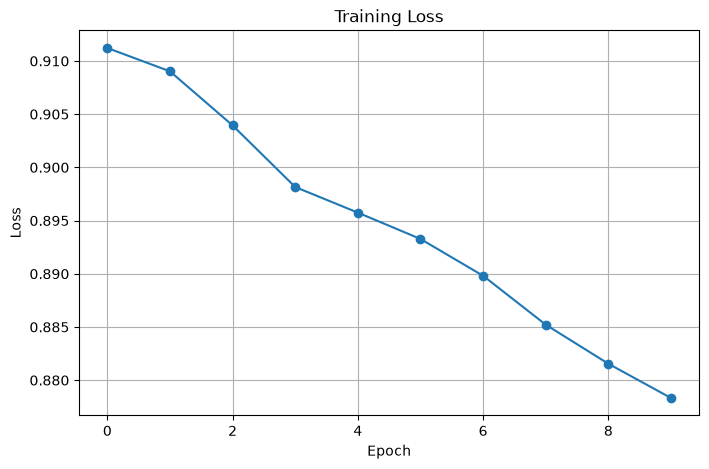

In [27]:
plt.figure(figsize=(8,5))
plt.plot(history["train_loss"],marker="o")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()
plt.show()

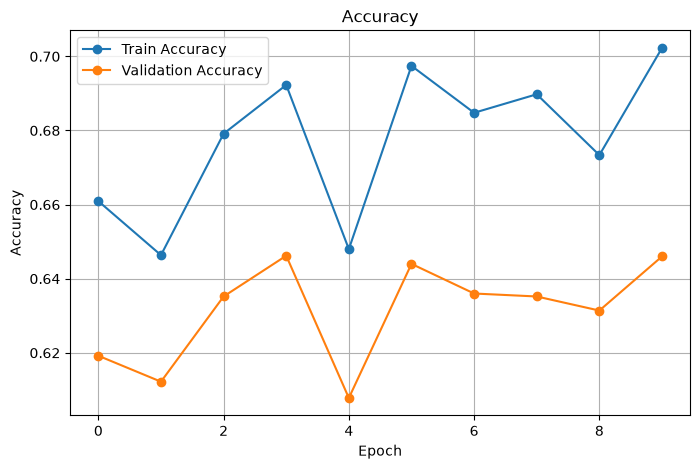

In [28]:
plt.figure(figsize=(8,5))
plt.plot(history["train_acc"],marker="o",label="Train Accuracy")
plt.plot(history["val_acc"],marker="o",label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Test set evaluation

In [29]:
test_acc = accuracy(model,x_test,y_test,batch_size=32)
print(f"Test accuracy: {test_acc:.4f}")

Test accuracy: 0.6555


# Predictions

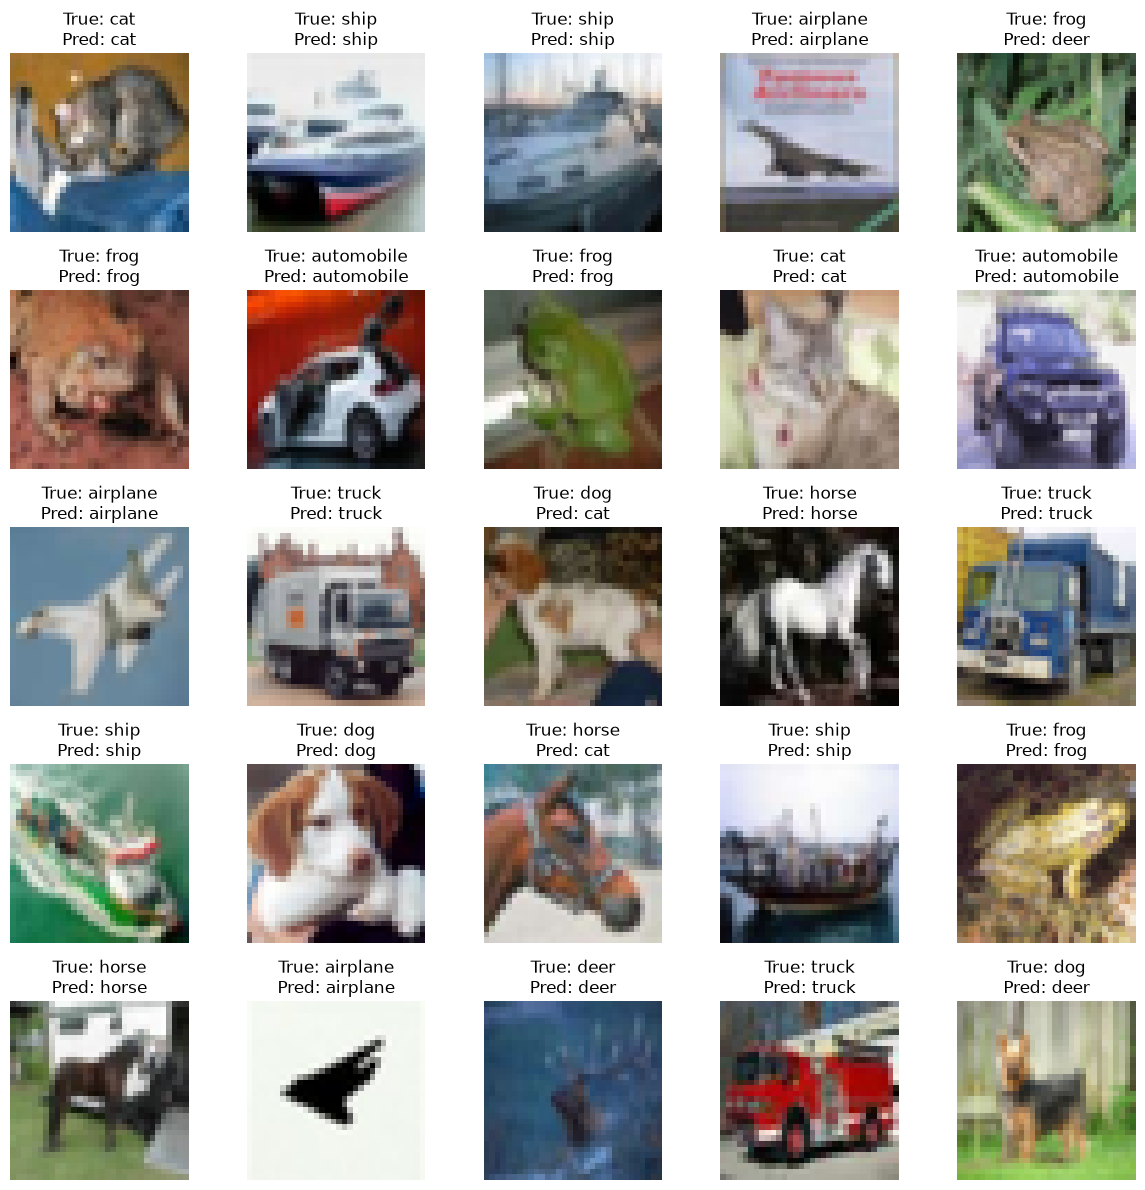

In [22]:
predictions = model.predict(x_test[:25])
fig,axes = plt.subplots(5,5,figsize=(12,12))

for i,ax in enumerate(axes.flat):
    img = x_test[i].transpose(1,2,0)
    ax.imshow(img)
    ax.set_title(f"True: {classes[y_test[i]]}\nPred: {classes[predictions[i]]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Save the trained parameters

In [23]:
params = {
    "conv1_w":model.conv1.w,
    "conv1_b":model.conv1.b,
    "conv2_w":model.conv2.w,
    "conv2_b":model.conv2.b,
    "dense_w":model.dense.w,
    "dense_b":model.dense.b
}

np.savez("cnn_cifar10_numpy_params.npz",**params)
print("Saved parameters to cnn_cifar10_numpy_params.npz")

Saved parameters to cnn_cifar10_numpy_params.npz


# Notes

- Conv2D uses `im2col` in forward and matrix multiplication for weight gradients.
- `col2im` adds patch gradients back to input positions. Overlapping receptive fields must accumulate.
- ReLU passes gradients only where its forward input was positive.
- MaxPool routes gradient to the maximum location recorded in forward.
- DenseLayer produces the class logits.
- SoftmaxCrossEntropy computes the loss and gradient with respect to logits.
- SGD updates weights and biases.
- This is a NumPy implementation for understanding the mechanics; optimized frameworks are much faster.